# How One Line of Imputation Inflated a Heart Disease Model

My first model on this dataset reached **0.98 AUC**. It looked excellent, and it was wrong. The cause was a single preprocessing step: filling missing values using each patient's diagnosis.

Once corrected, the same random forest on the same 251 test patients scores **0.87 AUC**.

**In this notebook:**

- reproduce the leak and see exactly how it works;
- fix it with a scikit-learn pipeline;
- see why cross-validation did not catch it, and how to spot it;
- compare three models and test them across four hospitals;
- check calibration and variable importance.

I found this error in my own Master's thesis work after defending it, and I corrected the published dataset. Version 1 of this dataset contained the leak; **version 2**, used here, leaves missing values empty.

> **Medical disclaimer.** This work is for research and education. It is not a diagnostic tool and must not replace the advice of a healthcare professional.

## 1. Setup

The notebook needs **version 2** of the dataset, which keeps missing values empty and adds a `centre` column.

In [1]:
import glob
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, brier_score_loss, confusion_matrix, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e4e3df", "axes.axisbelow": True, "lines.linewidth": 2})
pd.set_option("display.float_format", "{:.3f}".format)

RANDOM_STATE = 42
TARGET, CENTRE = "target", "centre"
NUMERIC = ["age", "trestbps", "chol", "thalach", "oldpeak", "ca"]
CATEGORICAL = ["cp", "restecg", "slope", "thal"]
BINARY = ["sex", "fbs", "exang"]
FEATURES = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg", "thalach", "exang", "oldpeak", "slope", "ca", "thal"]
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
MODEL_COLORS = {"Logistic regression": BLUE, "SVM": ORANGE, "Random forest": AQUA}

candidates = glob.glob("/kaggle/input/**/heart_uci_combined.csv", recursive=True)
candidates.append("../data/processed/heart_uci_combined.csv")
df = pd.read_csv(next(path for path in candidates if Path(path).exists()))
assert CENTRE in df.columns, "This notebook needs version 2 of the dataset."
print(f"{len(df)} patients, {int(df[TARGET].sum())} diseased, {int((df[TARGET] == 0).sum())} healthy")

834 patients, 463 diseased, 371 healthy


In [2]:
def build_preprocessor():
    numeric = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
    categorical = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore")),
    ])
    return ColumnTransformer([
        ("num", numeric, NUMERIC),
        ("cat", categorical, CATEGORICAL),
        ("bin", SimpleImputer(strategy="most_frequent"), BINARY),
    ])


def build_pipeline(model):
    return Pipeline([("prep", build_preprocessor()), ("model", model)])


# Hyperparameters come from a search run on the training set only, in the project repository.
def build_models():
    return {
        "Logistic regression": LogisticRegression(C=0.1, max_iter=5000, random_state=RANDOM_STATE),
        "SVM": SVC(C=10, gamma="scale", probability=True, random_state=RANDOM_STATE),
        "Random forest": RandomForestClassifier(n_estimators=100, class_weight="balanced", random_state=RANDOM_STATE),
    }


def evaluate(y_true, probability):
    predicted = (np.asarray(probability) >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, predicted, labels=[0, 1]).ravel()
    return {
        "Accuracy": accuracy_score(y_true, predicted),
        "AUC": roc_auc_score(y_true, probability),
        "Sensitivity": tp / (tp + fn),
        "Specificity": tn / (tn + fp),
        "Brier": brier_score_loss(y_true, probability),
    }


train_index, test_index = train_test_split(df.index, test_size=0.30, random_state=RANDOM_STATE, stratify=df[TARGET])
print(f"Train: {len(train_index)} patients | Test: {len(test_index)} patients")

Train: 583 patients | Test: 251 patients


## 2. The data: four hospitals, very different missingness

Missing values are not random here. `ca` is almost absent outside Cleveland, and disease prevalence ranges from about 38% to 93% depending on the center. Any preprocessing shortcut can therefore carry a lot of information.

,patients,diseased_rate
centre,,
Cleveland,303,0.459
Hungarian,272,0.379
Long Beach VA,142,0.789
Switzerland,117,0.932


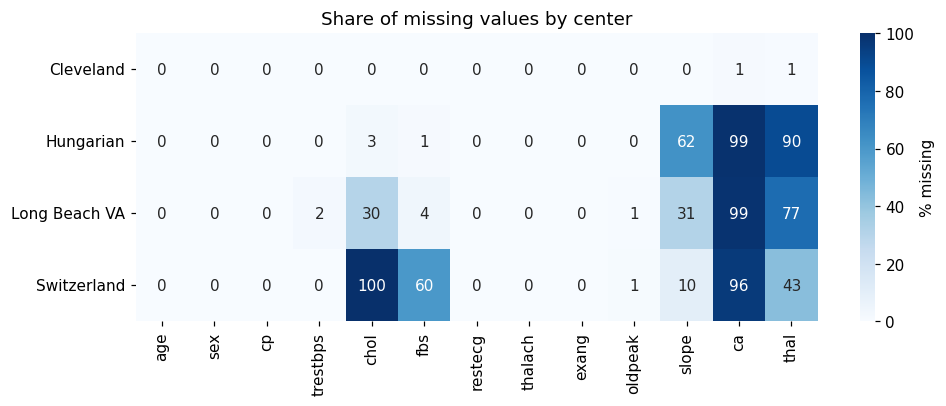

In [3]:
summary = df.groupby(CENTRE).agg(patients=(TARGET, "size"), diseased_rate=(TARGET, "mean"))
display(summary.sort_values("patients", ascending=False))

rates = df.groupby(CENTRE)[FEATURES].apply(lambda group: group.isna().mean() * 100)
fig, ax = plt.subplots(figsize=(10, 3.4))
sns.heatmap(rates, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100, cbar_kws={"label": "% missing"}, ax=ax)
ax.set(xlabel="", ylabel="", title="Share of missing values by center")
ax.grid(False)
plt.show()

## 3. Reproducing the leak

The tempting version fills each missing value with the median of **the patient's own diagnosis group**, before splitting the data. It looks harmless: one `groupby` and the table is complete.

Version 1 of this dataset was built this way, and it also kept impossible cholesterol values of 0.

In [4]:
def impute_with_the_target(data):
    data = data.copy()
    for column in NUMERIC:
        data[column] = data.groupby(TARGET)[column].transform(lambda values: values.fillna(values.median()))
    for column in CATEGORICAL + BINARY:
        data[column] = data[column].fillna(data[column].mode()[0])
    return data


leaky = impute_with_the_target(df)
missing_ca = df["ca"].isna()

print(f"Patients with no recorded ca: {missing_ca.sum()} ({missing_ca.mean():.1%})")
print("\nImputed ca value by true diagnosis:")
display(pd.crosstab(leaky.loc[missing_ca, "ca"], leaky.loc[missing_ca, TARGET], rownames=["imputed ca"], colnames=["target"]))

measured = df.loc[~missing_ca, ["ca", TARGET]].corr().iloc[0, 1]
imputed = leaky.loc[missing_ca, ["ca", TARGET]].corr().iloc[0, 1]
print(f"Correlation between ca and target on measured values: {measured:.3f}")
print(f"Correlation between ca and target on imputed values:  {imputed:.3f}")

Patients with no recorded ca: 525 (62.9%)

Imputed ca value by true diagnosis:


target,0,1
imputed ca,,
0.000,206,0
1.000,0,319


Correlation between ca and target on measured values: 0.456


Correlation between ca and target on imputed values:  1.000


For every patient whose `ca` was filled in, the value is now the answer: 0 means healthy and 1 means diseased. A model only has to read it.

## 4. The fix: split first, impute inside a pipeline

Below, the same random forest and the same patients are evaluated twice. The only difference is where and how missing values are filled.

,Accuracy,AUC,Sensitivity,Specificity,Brier
Target-based imputation (leak),0.928,0.980,0.935,0.920,0.057
Imputation inside the pipeline,0.785,0.869,0.842,0.714,0.144


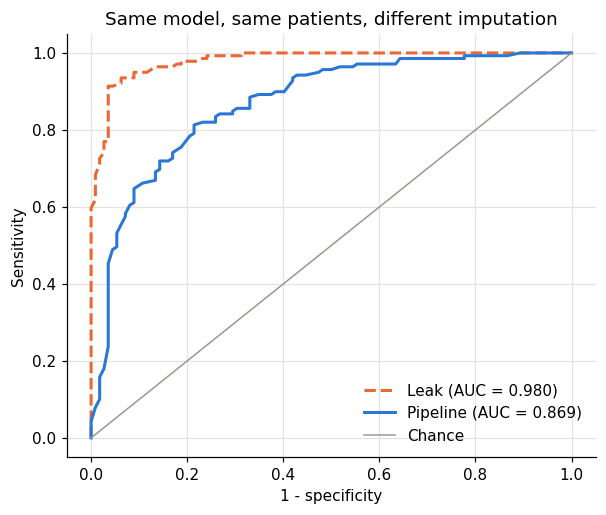

In [5]:
def fit_and_score(data, model):
    fitted = build_pipeline(model).fit(data.loc[train_index, FEATURES], data.loc[train_index, TARGET])
    probability = fitted.predict_proba(data.loc[test_index, FEATURES])[:, 1]
    return fitted, probability, evaluate(data.loc[test_index, TARGET], probability)


rf_leaky, p_leaky, m_leaky = fit_and_score(leaky, build_models()["Random forest"])
rf_clean, p_clean, m_clean = fit_and_score(df, build_models()["Random forest"])
comparison = pd.DataFrame({"Target-based imputation (leak)": m_leaky, "Imputation inside the pipeline": m_clean}).T
display(comparison)

y_test = df.loc[test_index, TARGET]
fig, ax = plt.subplots(figsize=(6.2, 5))
for probability, label, color, style in [(p_leaky, "Leak", ORANGE, "--"), (p_clean, "Pipeline", BLUE, "-")]:
    fpr, tpr, _ = roc_curve(y_test, probability)
    ax.plot(fpr, tpr, color=color, linestyle=style, label=f"{label} (AUC = {roc_auc_score(y_test, probability):.3f})")
ax.plot([0, 1], [0, 1], color="#9a9890", linewidth=1, label="Chance")
ax.set(xlabel="1 - specificity", ylabel="Sensitivity", title="Same model, same patients, different imputation")
ax.legend(loc="lower right", frameon=False)
plt.show()

### Would cross-validation have caught it?

No. Once the target has been written into the features, every fold inherits the leak. Cross-validation is only as honest as the data it receives.

In [6]:
def cross_validate(data, n_splits=10):
    folds = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
    rows = {}
    for name, model in build_models().items():
        scores = []
        for train, test in folds.split(data[FEATURES], data[TARGET]):
            fitted = build_pipeline(model).fit(data.iloc[train][FEATURES], data.iloc[train][TARGET])
            scores.append(evaluate(data.iloc[test][TARGET], fitted.predict_proba(data.iloc[test][FEATURES])[:, 1]))
        table = pd.DataFrame(scores)
        rows[name] = {metric: f"{table[metric].mean():.3f} ± {table[metric].std(ddof=0):.3f}" for metric in ["Accuracy", "AUC", "Sensitivity", "Specificity"]}
    return pd.DataFrame(rows).T


print("10-fold cross-validation on the leaky data")
display(cross_validate(leaky))
print("10-fold cross-validation with imputation inside each fold")
display(cross_validate(df))

10-fold cross-validation on the leaky data


,Accuracy,AUC,Sensitivity,Specificity
Logistic regression,0.911 ± 0.032,0.955 ± 0.029,0.922 ± 0.034,0.898 ± 0.053
SVM,0.896 ± 0.029,0.953 ± 0.019,0.916 ± 0.024,0.871 ± 0.070
Random forest,0.927 ± 0.022,0.977 ± 0.009,0.931 ± 0.013,0.922 ± 0.056


10-fold cross-validation with imputation inside each fold


,Accuracy,AUC,Sensitivity,Specificity
Logistic regression,0.796 ± 0.051,0.884 ± 0.040,0.827 ± 0.052,0.758 ± 0.086
SVM,0.794 ± 0.048,0.848 ± 0.047,0.855 ± 0.062,0.717 ± 0.078
Random forest,0.807 ± 0.037,0.875 ± 0.037,0.851 ± 0.042,0.752 ± 0.049


### How to spot this kind of leak

Feature importance is a cheap alarm. The next chart measures how much the test AUC drops when each variable is shuffled.

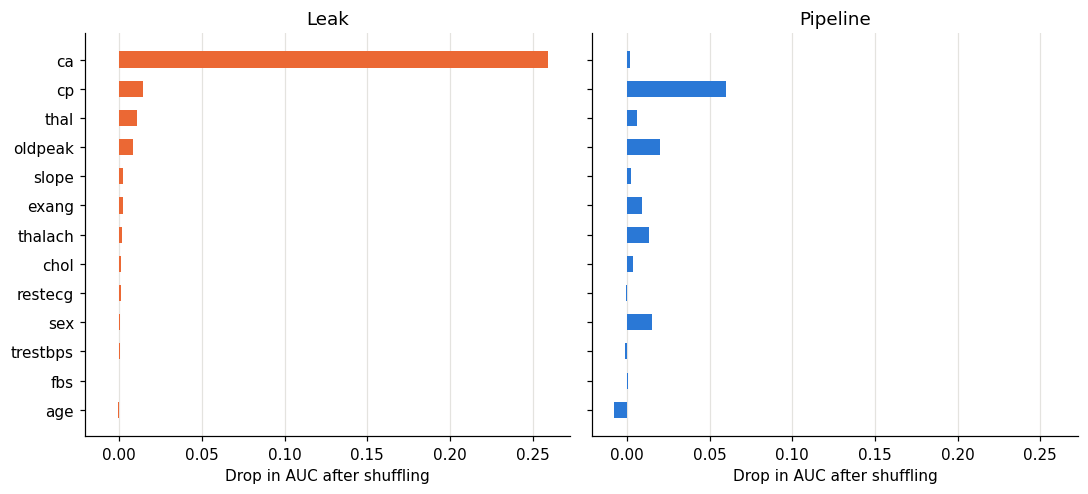

In [7]:
def importance(model, data):
    result = permutation_importance(model, data.loc[test_index, FEATURES], data.loc[test_index, TARGET], scoring="roc_auc", n_repeats=20, random_state=RANDOM_STATE)
    return pd.Series(result.importances_mean, index=FEATURES)


importances = pd.DataFrame({"Leak": importance(rf_leaky, leaky), "Pipeline": importance(rf_clean, df)})
order = importances["Leak"].sort_values().index
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6), sharey=True, sharex=True)
for ax, (label, color) in zip(axes, [("Leak", ORANGE), ("Pipeline", BLUE)]):
    ax.barh(order, importances.loc[order, label], color=color, height=0.55)
    ax.set(title=label, xlabel="Drop in AUC after shuffling")
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

A practical checklist:

- Is the score far above published results on the same data?
- Does one variable dominate, especially one that is often missing?
- Does any preprocessing step read the target or the full dataset?
- Compare each variable's relationship with the target on measured values and on filled-in values.

## 5. Comparing the three models

Results on the held-out test set, with preprocessing fitted on the training set only.

In [8]:
fitted_models, test_probabilities, rows = {}, {}, {}
for name, model in build_models().items():
    fitted_models[name], test_probabilities[name], rows[name] = fit_and_score(df, model)
display(pd.DataFrame(rows).T)

,Accuracy,AUC,Sensitivity,Specificity,Brier
Logistic regression,0.809,0.889,0.849,0.759,0.134
SVM,0.765,0.844,0.820,0.696,0.160
Random forest,0.785,0.869,0.842,0.714,0.144


The project selected its model **before** looking at this table, using the training set only: highest cross-validated sensitivity, with specificity of at least 0.70. That rule chose the SVM, by a very small margin. The SVM then finished last here. I did not switch models afterwards, since choosing from the test set would invalidate this evaluation. The differences between models are small compared with their uncertainty.

## 6. Does the model travel? Train on three centers, test on the fourth

A random split mixes patients from every hospital. Holding out a whole center is closer to deploying the model somewhere new.

Model,Logistic regression,Random forest,SVM
Center,,,
Cleveland,0.875,0.841,0.811
Hungarian,0.883,0.845,0.773
Long Beach VA,0.684,0.642,0.566
Switzerland,0.742,0.803,0.722


,Healthy patients,Accuracy,AUC,Sensitivity,Specificity
Center,,,,,
Cleveland,164,0.752,0.811,0.827,0.689
Hungarian,169,0.651,0.773,0.854,0.527
Switzerland,8,0.615,0.722,0.606,0.750
Long Beach VA,30,0.761,0.566,0.902,0.233


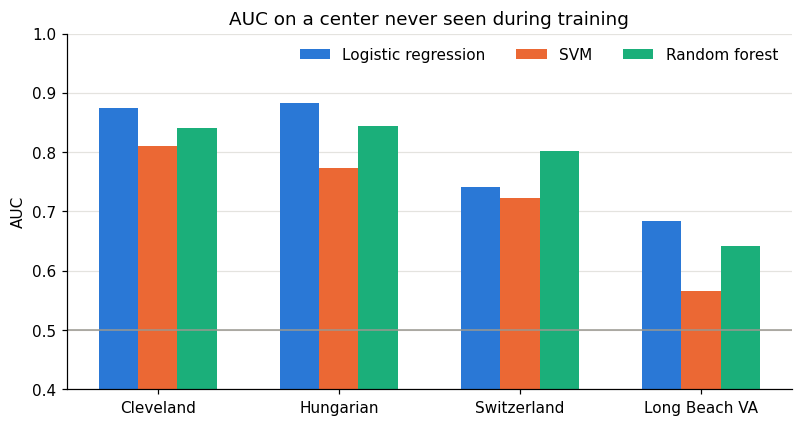

In [9]:
records = []
for centre in df[CENTRE].unique():
    train, test = df[df[CENTRE] != centre], df[df[CENTRE] == centre]
    for name, model in build_models().items():
        fitted = build_pipeline(model).fit(train[FEATURES], train[TARGET])
        scores = evaluate(test[TARGET], fitted.predict_proba(test[FEATURES])[:, 1])
        records.append({"Center": centre, "Healthy patients": int((test[TARGET] == 0).sum()), "Model": name, **scores})
centres = pd.DataFrame(records)
display(centres.pivot(index="Center", columns="Model", values="AUC"))
display(centres[centres["Model"] == "SVM"].drop(columns=["Model", "Brier"]).set_index("Center"))

center_order = ["Cleveland", "Hungarian", "Switzerland", "Long Beach VA"]
fig, ax = plt.subplots(figsize=(8.5, 4.2))
sns.barplot(data=centres, x="Center", y="AUC", hue="Model", order=center_order, palette=MODEL_COLORS, width=0.65, saturation=1, ax=ax)
ax.axhline(0.5, color="#9a9890", linewidth=1)
ax.set(xlabel="", ylim=(0.4, 1), title="AUC on a center never seen during training")
ax.legend(frameon=False, ncols=3, loc="upper right")
plt.show()

Logistic regression holds up best at Cleveland and in Hungary. Every model degrades at Long Beach VA, where the SVM is barely better than chance. The Swiss results rely on only 8 healthy patients and should be read with care. A model trained on this data needs local validation before it is used on a new population.

Hyperparameters are kept fixed here to keep the notebook fast. The repository repeats the search on each set of three training centers, so its per-center values differ, although the conclusion is the same.

## 7. Calibration and variable importance of the selected model

When an application displays a probability, the number itself must be meaningful, not only the ranking of patients.

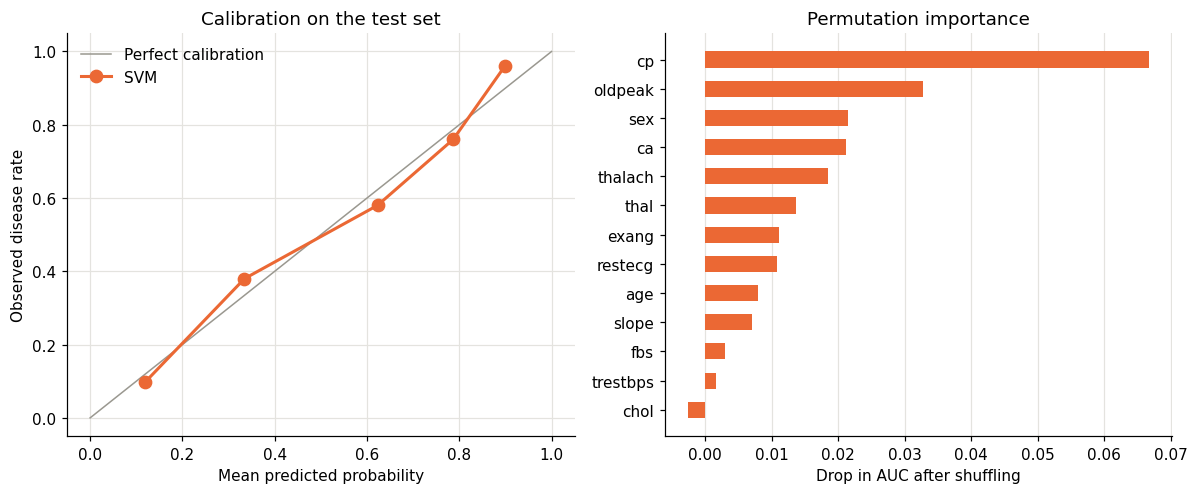

Brier score: 0.160


In [10]:
svm_probability = test_probabilities["SVM"]
observed, predicted = calibration_curve(y_test, svm_probability, n_bins=5, strategy="quantile")
svm_importance = importance(fitted_models["SVM"], df).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
axes[0].plot([0, 1], [0, 1], color="#9a9890", linewidth=1, label="Perfect calibration")
axes[0].plot(predicted, observed, marker="o", markersize=8, color=ORANGE, label="SVM")
axes[0].set(xlabel="Mean predicted probability", ylabel="Observed disease rate", title="Calibration on the test set")
axes[0].legend(frameon=False, loc="upper left")
axes[1].barh(svm_importance.index, svm_importance.values, color=ORANGE, height=0.55)
axes[1].set(xlabel="Drop in AUC after shuffling", title="Permutation importance")
axes[1].grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
print(f"Brier score: {brier_score_loss(y_test, svm_probability):.3f}")

Calibration is reasonable on this sample, but it was checked on one sample of 251 patients. Permutation importance describes how this model uses its inputs and says nothing about causality.

## 8. Takeaways

In [11]:
display(Markdown(f"""
- **The leak was worth {m_leaky['AUC'] - m_clean['AUC']:.3f} AUC points on this run:** {m_leaky['AUC']:.3f} with target-based imputation, {m_clean['AUC']:.3f} with imputation inside the pipeline.
- **Accuracy moved from {m_leaky['Accuracy']:.1%} to {m_clean['Accuracy']:.1%}** with the same model and the same test patients.
- **Cross-validation did not reveal the problem**, because the leak happened before the split.
"""))


- **The leak was worth 0.110 AUC points on this run:** 0.980 with target-based imputation, 0.869 with imputation inside the pipeline.
- **Accuracy moved from 92.8% to 78.5%** with the same model and the same test patients.
- **Cross-validation did not reveal the problem**, because the leak happened before the split.


**What I would do differently from the start**

1. Split the data before any step that learns from it.
2. Keep imputation, scaling and encoding inside a pipeline.
3. Never let the target inform a feature.
4. Report uncertainty, and validate across sites whenever the data allow it.

**Limitations.** The data are historical and come from the USA and Europe. `ca` and `thal` require specialized examinations and are mostly missing outside Cleveland. No clinical validation was performed.

**Medical disclaimer.** This work is for research and education. It is not a diagnostic tool and must not replace the advice of a healthcare professional.

**More.** Full pipeline, API, tests, nested cross-validation (in which the optimization is repeated inside each fold) and a detailed comparison with the original thesis results: [github.com/Abdoul-wakilou/cardio_predict_model](https://github.com/Abdoul-wakilou/cardio_predict_model). Numbers may vary slightly with library versions.

**Data.** Janosi, A., Steinbrunn, W., Pfisterer, M., and Detrano, R. (1988). *Heart Disease*. UCI Machine Learning Repository. https://doi.org/10.24432/C52P4X

*Abdoul-Wakilou TIGA*